<a href="https://colab.research.google.com/github/juliamota1/CN-unifesp/blob/main/Tarefa_Interpola%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Atividade Erro Interpolação

Julia dos Santos Mota - 185256

### Codigos disponibilizados na atividade

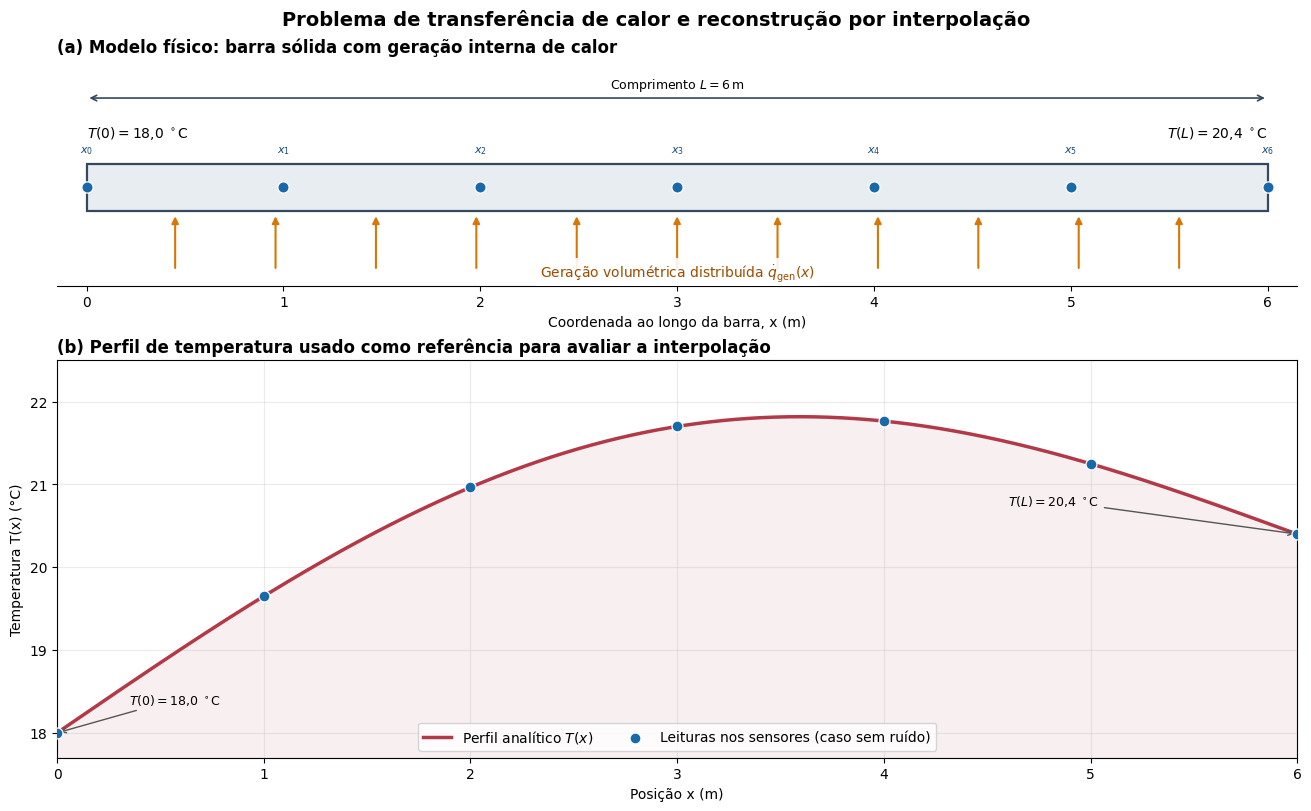

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:

# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1) Interpolação com dados exatos

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


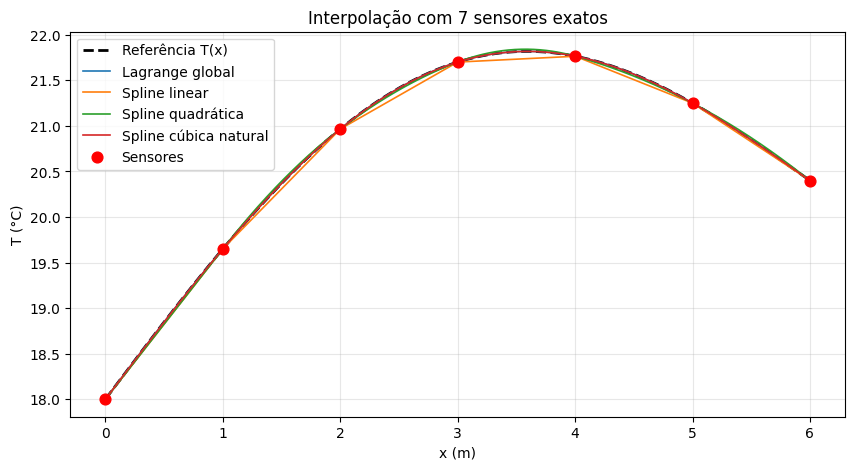

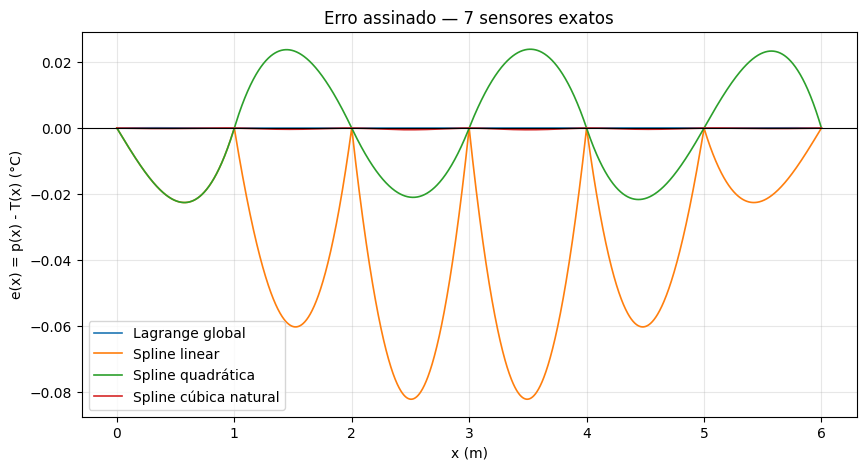

In [ ]:
# Métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Gráfico das temperaturas
plt.figure(figsize=(10, 5))
plt.plot(x_fino, T_fino, 'k--', lw=2, label='Referência T(x)')
for nome, metodo in metodos_7.items():
    plt.plot(x_fino, metodo(x_fino), lw=1.2, label=nome)
plt.scatter(x_nos_7, y_nos_7, s=60, c='red', zorder=5, label='Sensores')
plt.xlabel('x (m)'); plt.ylabel('T (°C)')
plt.title('Interpolação com 7 sensores exatos')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Gráfico dos erros assinados
plt.figure(figsize=(10, 5))
for nome, metodo in metodos_7.items():
    erro = metodo(x_fino) - T_fino
    plt.plot(x_fino, erro, lw=1.2, label=nome)
plt.axhline(0, color='k', lw=0.8)
plt.xlabel('x (m)'); plt.ylabel('e(x) = p(x) - T(x) (°C)')
plt.title('Erro assinado — 7 sensores exatos')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Etapa 2) Número e posições dos sensores

,N,Distribuição,Emax (°C),RMSE (°C)
0,5,Equiespaçado,4.530257e-03,2.159567e-03
1,5,Chebyshev,2.326599e-03,1.532697e-03
2,9,Equiespaçado,1.043537e-06,3.438146e-07
3,9,Chebyshev,2.167582e-07,1.202332e-07
4,13,Equiespaçado,5.912781e-11,1.545757e-11
5,13,Chebyshev,3.623768e-12,1.932044e-12
6,17,Equiespaçado,1.989520e-12,2.445428e-13
7,17,Chebyshev,1.421085e-14,3.854181e-15


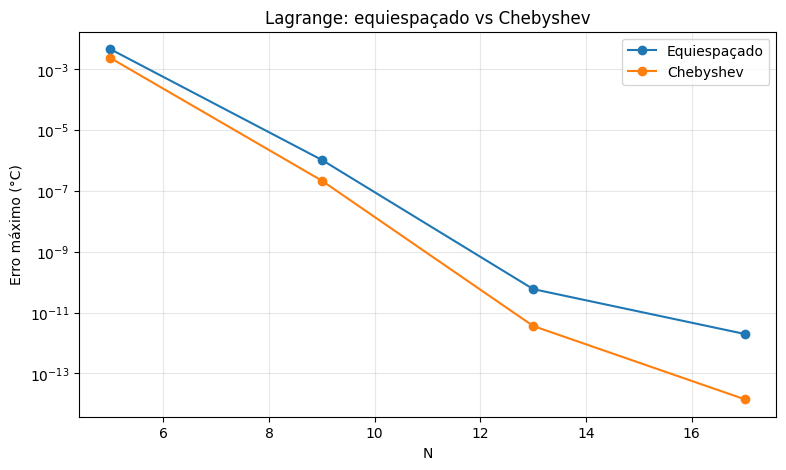

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

resultados = []
for N in [5, 9, 13, 17]:
    for tipo, x_nos in [
        ("Equiespaçado", np.linspace(x_min, x_max, N)),
        ("Chebyshev",    nos_chebyshev_lobatto(x_min, x_max, N)),
    ]:
        interp = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        erro = interp(x_fino) - T_fino
        resultados.append({
            "N": N, "Distribuição": tipo,
            "Emax (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
        })

tabela_nos = pd.DataFrame(resultados)
display(tabela_nos)

# Visualização (opcional): erro máximo em escala log
for tipo in ["Equiespaçado", "Chebyshev"]:
    sub = tabela_nos[tabela_nos["Distribuição"] == tipo]
    plt.semilogy(sub["N"], sub["Emax (°C)"], 'o-', label=tipo)
plt.xlabel('N'); plt.ylabel('Erro máximo (°C)')
plt.title('Lagrange: equiespaçado vs Chebyshev')
plt.legend(); plt.grid(alpha=0.3, which='both'); plt.show()

**Conclusão da Etapa 2:**

O aumento do número de sensores reduziu significativamente os erros de interpolação. Além disso, a distribuição de Chebyshev apresentou resultados melhores do que a distribuição igualmente espaçada nos quatro casos estudados.

Isso acontece porque os sensores de Chebyshev ficam mais concentrados nas extremidades, ajudando a controlar as oscilações do polinômio global.

É importante lembrar que esse resultado depende do perfil analisado e não significa que Chebyshev será sempre superior para qualquer função.

## Etapa 3) Estudo de caso e decisão técnica

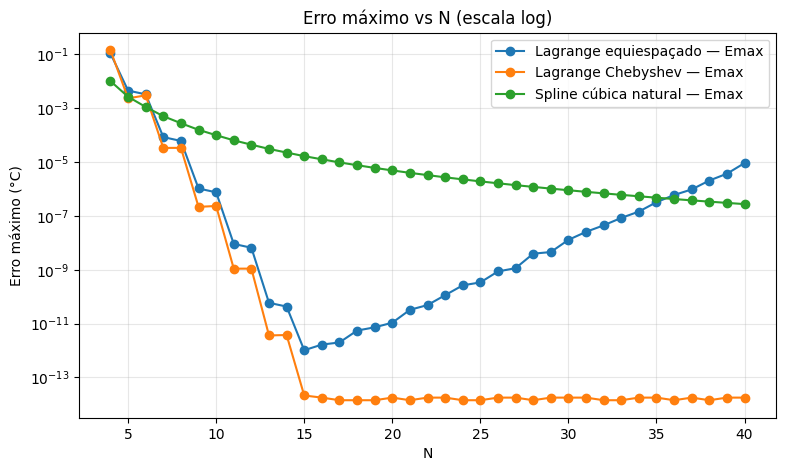

In [ ]:
import time

Ns = np.arange(4, 41)
res3 = []
for N in Ns:
    x_eq = np.linspace(x_min, x_max, N)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    y_ch = temperatura_real(x_ch)

    # Lagrange equiespaçado
    t0 = time.perf_counter()
    lag_eq = BarycentricInterpolator(x_eq, y_eq)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter(); e_eq = lag_eq(x_fino) - T_fino
    t_eval = time.perf_counter() - t0
    res3.append({"N": N, "Método": "Lagrange equiespaçado",
                 "Emax": np.max(np.abs(e_eq)),
                 "RMSE": np.sqrt(np.mean(e_eq**2)),
                 "t_build": t_build, "t_eval": t_eval})

    # Lagrange Chebyshev
    t0 = time.perf_counter()
    lag_ch = BarycentricInterpolator(x_ch, y_ch)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter(); e_ch = lag_ch(x_fino) - T_fino
    t_eval = time.perf_counter() - t0
    res3.append({"N": N, "Método": "Lagrange Chebyshev",
                 "Emax": np.max(np.abs(e_ch)),
                 "RMSE": np.sqrt(np.mean(e_ch**2)),
                 "t_build": t_build, "t_eval": t_eval})

    # Spline cúbica natural
    t0 = time.perf_counter()
    cs = CubicSpline(x_eq, y_eq, bc_type="natural")
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter(); e_cs = cs(x_fino) - T_fino
    t_eval = time.perf_counter() - t0
    res3.append({"N": N, "Método": "Spline cúbica natural",
                 "Emax": np.max(np.abs(e_cs)),
                 "RMSE": np.sqrt(np.mean(e_cs**2)),
                 "t_build": t_build, "t_eval": t_eval})

tabela3 = pd.DataFrame(res3)

# Gráfico log-log
plt.figure(figsize=(9, 5))
for m in tabela3["Método"].unique():
    sub = tabela3[tabela3["Método"] == m]
    plt.semilogy(sub["N"], sub["Emax"], 'o-', label=m + " — Emax")
plt.xlabel('N'); plt.ylabel('Erro máximo (°C)')
plt.title('Erro máximo vs N (escala log)')
plt.legend(); plt.grid(alpha=0.3, which='both'); plt.show()

**A análise dos resultados permite observar alguns comportamentos:**

1. **Lagrange equiespaçado**

Apresenta excelente precisão para o perfil estudado, principalmente quando aumenta o número de sensores. Entretanto, polinômios globais podem apresentar oscilações numéricas, especialmente perto das extremidades, dependendo da função e da distribuição dos nós.

2. **Lagrange com Chebyshev**

A distribuição de Chebyshev ajuda a controlar as oscilações nas extremidades. É uma alternativa interessante quando se deseja utilizar um polinômio global com muitos sensores.

3. **Spline cúbica natural**

Apresenta boa estabilidade, pois trabalha com polinômios separados por intervalos. Não precisa construir um único polinômio de grau muito elevado.

Nos testes deste perfil, a spline cúbica apresentou erros máximos e RMSE inferiores a 0,011 °C em toda a faixa de 4 a 40 sensores.

**Conclusão da Etapa 3:**

Não existe necessariamente um único método superior para todos os números de sensores. A escolha depende da precisão desejada, da quantidade de dados, da estabilidade numérica e do custo computacional.

Para esse problema, a spline cúbica natural é uma opção interessante por apresentar boa precisão e estabilidade, enquanto Lagrange pode ser extremamente preciso para o perfil suave utilizado.

## Etapa 4) Estudo de caso e decisão técnica


=== N = 7, sigma = 0.15 °C ===


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Spline linear,0.315811,0.130664,0.160218
1,Spline cúbica natural,0.321898,0.142521,0.168447
2,Lagrange global,0.374611,0.152335,0.182519
3,Spline quadrática,0.343856,0.152310,0.184893


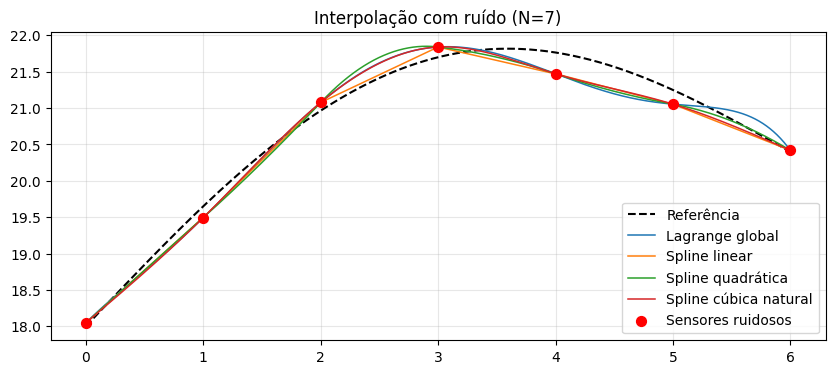


=== N = 13, sigma = 0.15 °C ===


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Spline linear,0.169086,0.068702,0.080164
1,Spline cúbica natural,0.179831,0.082485,0.098570
2,Spline quadrática,0.560183,0.151468,0.198665
3,Lagrange global,1.300720,0.184674,0.316299


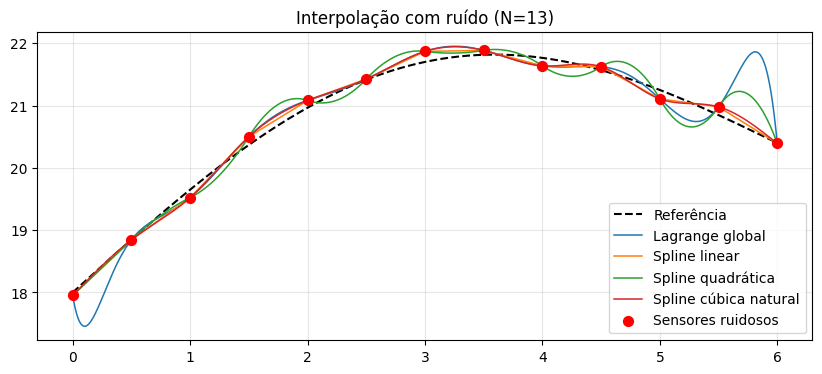

In [ ]:
rng = np.random.default_rng(42)
sigma = 0.15  # °C, ajuste conforme o enunciado

for N in [7, 13]:
    x_nos = np.linspace(x_min, x_max, N)
    y_ruido = temperatura_real(x_nos) + rng.normal(0, sigma, N)
    met = criar_metodos(x_nos, y_ruido)
    print(f"\n=== N = {N}, sigma = {sigma} °C ===")
    display(calcular_metricas(met, x_fino, T_fino))

    plt.figure(figsize=(10, 4))
    plt.plot(x_fino, T_fino, 'k--', label='Referência')
    for nome, m in met.items():
        plt.plot(x_fino, m(x_fino), lw=1.1, label=nome)
    plt.scatter(x_nos, y_ruido, c='red', s=50, zorder=5, label='Sensores ruidosos')
    plt.title(f'Interpolação com ruído (N={N})')
    plt.legend(); plt.grid(alpha=0.3); plt.show()

- **Que método escolheria com poucos sensores exatos e por quê?**

Escolheria a spline cúbica natural, pois ela consegue representar curvas suaves com boa precisão e evita a necessidade de construir um polinômio global de grau elevado.

Entretanto, se os sensores forem poucos e estiverem bem distribuídos, Lagrange também pode apresentar resultados excelentes, como observamos na primeira etapa.

---

- **Como a recomendação muda quando se aumenta o número de sensores?**


Com o aumento do número de sensores, podemos obter uma representação mais detalhada da temperatura.

Entretanto, utilizar muitos pontos em um único polinômio global pode causar oscilações numéricas, principalmente nas extremidades.

Nesse caso, a spline cúbica se torna uma alternativa interessante por trabalhar com intervalos menores. Se optarmos por Lagrange, podemos utilizar nós de Chebyshev para melhorar o comportamento nas extremidades.

---

- **O que faria quando os sensores apresentam ruído?**


Quando os sensores apresentam ruído, os valores medidos podem não representar exatamente a temperatura verdadeira.

Nesse cenário, não seria adequado simplesmente utilizar uma interpolação que passa obrigatoriamente por todos os pontos, pois ela também pode reproduzir as oscilações causadas pelos erros de medição.

Utilizaria métodos de ajuste, como a regressão por mínimos quadrados, para encontrar uma curva que represente a tendência geral dos dados sem acompanhar cada variação individual.

Também verificaria a calibração dos sensores e, se possível, faria medições repetidas.

---

- **Que cuidados adotaria perto das extremidades?**

Daria atenção especial às extremidades porque os polinômios globais podem apresentar oscilações nessa região.

Também verificaria se os sensores estão posicionados próximos às extremidades e se as temperaturas prescritas nas bordas estão sendo respeitadas.

Além disso, evitaria estimar temperaturas fora do intervalo monitorado sem um modelo físico que justificasse essa extrapolação.

---

- **Que limitações permanecem quando a temperatura verdadeira não é conhecida?**


Quando não conhecemos a temperatura verdadeira, não conseguimos calcular diretamente o erro máximo, o MAE ou o RMSE em relação à solução real.

Podemos avaliar a consistência das medições, comparar diferentes métodos, analisar a dispersão dos dados e utilizar modelos físicos para verificar se os resultados são coerentes.

Porém, uma interpolação visualmente adequada não garante que a temperatura estimada seja exatamente a verdadeira.

---
**Conclusão geral da Etapa 4**

A escolha do método de interpolação depende da quantidade de sensores, da distribuição dos pontos e da qualidade das medições.

Para dados exatos, os métodos de interpolação podem apresentar resultados bastante precisos. Entretanto, quando existe ruído, é importante considerar métodos de ajuste, como mínimos quadrados, que não precisam passar exatamente por todos os pontos medidos.

Assim, a escolha deve considerar não apenas a precisão matemática, mas também a estabilidade numérica e as condições reais de medição.